# Problem Statement

Shopee merupakan salah satu marketplace terbesar di Asia Tenggara, termasuk di Malaysia. Dengan ribuan seller dan jutaan listing produk, persaingan di platform ini sangat ketat. Seller, terutama yang baru, sering kesulitan menentukan kategori produk yang tepat, lokasi sumber barang yang strategis, serta strategi harga dan diskon yang efektif untuk mendorong penjualan. Tanpa pemahaman terhadap pola pasar, seller berisiko memilih kategori yang terlalu jenuh, menetapkan harga yang tidak kompetitif, atau gagal membangun kepercayaan pembeli.
    
Oleh karena itu, diperlukan analisis eksploratif terhadap data listing produk Shopee Malaysia untuk memahami distribusi kategori, sebaran kota asal pengiriman, struktur harga, serta hubungan antara diskon, rating, favorit, dan jumlah terjual, sebagai dasar rekomendasi strategi bagi seller.

# 5W + 1H

- Kategori produk apa yang paling banyak dan paling kompetitif, dan bagaimana kisaran harganya?
- Dari kota atau negara mana produk paling banyak dikirim?
- Variabel apa yang berhubungan dengan jumlah terjual (harga, diskon, rating, favorit)?
- Apakah besar diskon berpengaruh pada penjualan?

# Import Libraries

In [1]:
import numpy as np, re
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from wordcloud import WordCloud

# Load Data

In [2]:
df = pd.read_csv("20240121_shopee_sample_data (1).csv")
df.head()

,price_ori,delivery,item_category_detail,specification,title,w_date,link_ori,item_rating,seller_name,idElastic,price_actual,sitename,idHash,total_rating,id,total_sold,pict_link,favorite,timestamp,desc
0,25.80,"KL City, Kuala Lumpur",Shopee | Women's Bags | Shoulder Bags | Should...,Product Specifications Category Shopee Women's...,1081 PU SLING BAG KULIT leather Casual Beg Tan...,2023-04-27,https://shopee.com.my/1081-PU-SLING-BAG-KULIT-...,4.9,qqfwholesale,19ec9fdedd9fe3e14bc652950fc3c423,12.90,shopee,88f051f0a2dcf0d29191e0175b828938,179,88f051f0a2dcf0d29191e0175b828938,179,https://down-my.img.susercontent.com/file/my-1...,Favorite (128,1682553600000,🎉 WELCOME To QQF WHOLESALE \r\n😍 ALL item read...
1,1.41,NaN,Shopee | Home Appliances | Sewing Machines | S...,Product Specifications Category Shopee Home Ap...,Stat Chinese Traditional Frog Buttons Knot Che...,2023-04-27,https://shopee.com.my/Stat-Chinese-Traditional...,5.0,stationery.my,5322309be3b6d9c01d15fa19f5b7ad9a,0.75,shopee,472d22f58af3bb35cf28c6eed7088dc5,17,472d22f58af3bb35cf28c6eed7088dc5,17,https://down-my.img.susercontent.com/file/4147...,Favorite (19,1682553600000,Chinese Traditional Frog Buttons Knot Cheongsa...
2,8.50,"KL City, Kuala Lumpur",Shopee | Women's Bags | Handbags | Set Handbags,Product Specifications Category Shopee Women's...,N09 READY STOCK MYFOOYIN woman handbag set 2in...,2023-04-26,https://shopee.com.my/N09-READY-STOCK-MYFOOYIN...,4.9,fooyin88,7a36765d1e2ca2b6a5414ddfeedfefc3,8.50,shopee,ec6ce64f4b77efb38b6392818959f181,8.1k,ec6ce64f4b77efb38b6392818959f181,8.1k,https://down-my.img.susercontent.com/file/23da...,Favorite (21.5k,1682467200000,READY STOCK\nMEASUREMENT:\nLONG 26CM X HEIGHT ...
3,8.70,NaN,Shopee | Women Clothes | Maternity Wear | Inne...,Product Specifications Category Shopee Women C...,🔥Shocking Sale🔥Cotton Comfort Nursing Bra Brea...,2023-04-26,https://shopee.com.my/%F0%9F%94%A5Shocking-Sal...,4.9,vivi2002,7fc4ab69722e4f788f217b4c044f83eb,8.70,shopee,ef4e0e17fdc7d0125d8609dcc395bc3d,6.5k,ef4e0e17fdc7d0125d8609dcc395bc3d,6.5k,https://down-my.img.susercontent.com/file/df47...,Favorite (3.4k,1682467200000,PRODUCT DESCRIPTION\nMaterial:95%Cotton+5%Span...
4,3999.00,"KL City, Kuala Lumpur",Shopee | Cameras & Drones | DSLR Cameras | DSLRs,Product Specifications Category Shopee Cameras...,Canon EOS 70D 18-55mm IS STM Original+64gb+ext...,2023-04-26,https://shopee.com.my/Canon-EOS-70D-18-55mm-IS...,5.0,xpro.gadget,55608f901f4c5384f884de18227d4298,2739.00,shopee,568c2029fed7d22973ff96d0404a8ff8,10,568c2029fed7d22973ff96d0404a8ff8,10,https://down-my.img.susercontent.com/file/4d3a...,Favorite (132,1682467200000,Canon 70D\nHighlights\nEF-S 18-55mm f/3.5-5.6 ...


In [3]:
df.describe()

,price_ori,price_actual,timestamp
count,2.011200e+04,2.029700e+04,2.031200e+04
mean,9.989702e+04,9.893085e+04,1.683323e+12
std,9.971868e+06,9.926322e+06,5.114706e+08
min,0.000000e+00,0.000000e+00,1.682294e+12
25%,2.270000e+00,1.000000e+00,1.682899e+12
50%,1.990000e+01,1.000000e+01,1.683331e+12
75%,8.990000e+01,6.900000e+01,1.683850e+12
max,1.000000e+09,1.000000e+09,1.683936e+12


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20312 entries, 0 to 20311
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   price_ori             20112 non-null  float64
 1   delivery              6558 non-null   object 
 2   item_category_detail  20312 non-null  object 
 3   specification         20301 non-null  object 
 4   title                 20312 non-null  object 
 5   w_date                20312 non-null  object 
 6   link_ori              20312 non-null  object 
 7   item_rating           20301 non-null  object 
 8   seller_name           20301 non-null  object 
 9   idElastic             20312 non-null  object 
 10  price_actual          20297 non-null  float64
 11  sitename              20312 non-null  object 
 12  idHash                20312 non-null  object 
 13  total_rating          20301 non-null  object 
 14  id                    20312 non-null  object 
 15  total_sold         

# Handle Missing Value

In [5]:
df.drop(columns=['delivery'], inplace=True) # Kolom delivery dihapus karena hanya ada satu value dan banyak missing

In [6]:
df.dropna(inplace=True) # Menghapus baris yang terdapat missing value

In [7]:
df.to_csv('Shoppe_Sales.csv', index = False)

In [8]:
df = pd.read_csv("Shoppe_Sales.csv")
df.head()

,price_ori,item_category_detail,specification,title,w_date,link_ori,item_rating,seller_name,idElastic,price_actual,sitename,idHash,total_rating,id,total_sold,pict_link,favorite,timestamp,desc
0,25.80,Shopee | Women's Bags | Shoulder Bags | Should...,Product Specifications Category Shopee Women's...,1081 PU SLING BAG KULIT leather Casual Beg Tan...,2023-04-27,https://shopee.com.my/1081-PU-SLING-BAG-KULIT-...,4.9,qqfwholesale,19ec9fdedd9fe3e14bc652950fc3c423,12.90,shopee,88f051f0a2dcf0d29191e0175b828938,179,88f051f0a2dcf0d29191e0175b828938,179,https://down-my.img.susercontent.com/file/my-1...,Favorite (128,1682553600000,🎉 WELCOME To QQF WHOLESALE \r\n😍 ALL item read...
1,1.41,Shopee | Home Appliances | Sewing Machines | S...,Product Specifications Category Shopee Home Ap...,Stat Chinese Traditional Frog Buttons Knot Che...,2023-04-27,https://shopee.com.my/Stat-Chinese-Traditional...,5.0,stationery.my,5322309be3b6d9c01d15fa19f5b7ad9a,0.75,shopee,472d22f58af3bb35cf28c6eed7088dc5,17,472d22f58af3bb35cf28c6eed7088dc5,17,https://down-my.img.susercontent.com/file/4147...,Favorite (19,1682553600000,Chinese Traditional Frog Buttons Knot Cheongsa...
2,8.50,Shopee | Women's Bags | Handbags | Set Handbags,Product Specifications Category Shopee Women's...,N09 READY STOCK MYFOOYIN woman handbag set 2in...,2023-04-26,https://shopee.com.my/N09-READY-STOCK-MYFOOYIN...,4.9,fooyin88,7a36765d1e2ca2b6a5414ddfeedfefc3,8.50,shopee,ec6ce64f4b77efb38b6392818959f181,8.1k,ec6ce64f4b77efb38b6392818959f181,8.1k,https://down-my.img.susercontent.com/file/23da...,Favorite (21.5k,1682467200000,READY STOCK\nMEASUREMENT:\nLONG 26CM X HEIGHT ...
3,8.70,Shopee | Women Clothes | Maternity Wear | Inne...,Product Specifications Category Shopee Women C...,🔥Shocking Sale🔥Cotton Comfort Nursing Bra Brea...,2023-04-26,https://shopee.com.my/%F0%9F%94%A5Shocking-Sal...,4.9,vivi2002,7fc4ab69722e4f788f217b4c044f83eb,8.70,shopee,ef4e0e17fdc7d0125d8609dcc395bc3d,6.5k,ef4e0e17fdc7d0125d8609dcc395bc3d,6.5k,https://down-my.img.susercontent.com/file/df47...,Favorite (3.4k,1682467200000,PRODUCT DESCRIPTION\nMaterial:95%Cotton+5%Span...
4,3999.00,Shopee | Cameras & Drones | DSLR Cameras | DSLRs,Product Specifications Category Shopee Cameras...,Canon EOS 70D 18-55mm IS STM Original+64gb+ext...,2023-04-26,https://shopee.com.my/Canon-EOS-70D-18-55mm-IS...,5.0,xpro.gadget,55608f901f4c5384f884de18227d4298,2739.00,shopee,568c2029fed7d22973ff96d0404a8ff8,10,568c2029fed7d22973ff96d0404a8ff8,10,https://down-my.img.susercontent.com/file/4d3a...,Favorite (132,1682467200000,Canon 70D\nHighlights\nEF-S 18-55mm f/3.5-5.6 ...


# EDA

## Check Distribution

In [9]:
print(f"Skewness: {df['price_ori'].skew()}") # cek distribusi normal atau miring pada kolom

print(f"Kurtosis: {df['price_ori'].kurtosis()}") # cek distribusi normal atau miring pada kolom


Skewness: 93.34223315875313
Kurtosis: 10731.539089597074


Hasil menunjukan bahwa kolom tersebut mempunyai distribusi yang tidak normal, ini terjadi karena ada kesenjangan harga pada beberapa kategori, salah satu nya 'Automotive' karena mempunyai nilai yang sangat jauh berbeda dengan kategori pakaian

Gunakan Methode Tukey untuk menangani Outlier

In [10]:
q1 = df["price_ori"].quantile(0.25)
q3 = df["price_ori"].quantile(0.75)
iqr = q3 - q1

up_bound = q3 + 1.5 * iqr
low_bound = q1 - 1.5 * iqr

print(f"Batas Atas: {up_bound:.2f}") # Pengecekan Batas atas
print(f"Batas Bawah: {low_bound:.2f}") # Pengecekan Batas bawah

outlier_score = df["price_ori"][
    (df["price_ori"] < low_bound)
    | (df["price_ori"] > up_bound)
]
no_outlier_score = df["price_ori"][
    (df["price_ori"] >= low_bound)
    & (df["price_ori"] <= up_bound)
]

print(
    f'Persentase outlier_score: {len(outlier_score)*100/len(df["price_ori"]):.2f}%%' # Menghitung presentasi nilai outlier
)

Batas Atas: 209.01
Batas Bawah: -121.95
Persentase outlier_score: 10.79%%


Cek pada Grafik

<Axes: >

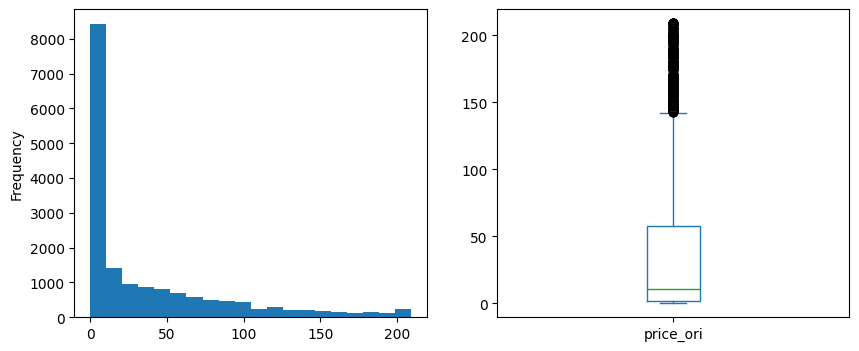

In [11]:
fig, ax = plt.subplots(ncols=2, figsize=(10, 4))

no_outlier_score.plot(kind="hist", bins=20, ax=ax[0])
no_outlier_score.plot(kind="box", ax=ax[1])

Setelah dilakukan handle menggunakan Tukey data memang masih terdapat Outlier namun tidak perlu dilakukan sampai bersih karena akan menghilangkan beberapa nilai pada data

## Check Product List

In [28]:
df["w_date"] = pd.to_datetime(df["w_date"]) # Mengubah type kolom w_date menjadi datetime
df["w_date"]

0       2023-04-27
1       2023-04-27
2       2023-04-26
3       2023-04-26
4       2023-04-26
           ...    
19024   2023-05-13
19025   2023-05-13
19026   2023-05-13
19027   2023-05-13
19028   2023-05-13
Name: w_date, Length: 19027, dtype: datetime64[ns]

Cek kolom 'specification' karena mempunyai value yang panjang yang bisa dijadikan value tambahan di kolom baru


In [29]:
df['specification'].value_counts() # Cek value pada kolom

specification
Product Specifications Category Shopee Automotive Automobiles Condition Used BrandHonda Condition Used Warranty Duration 12 Months Automobile Type Sedan & Hatchback Country of Origin Japan Electric No Warranty Type Carsome Warranty Fuel Type Petrol Stock 1 Ships From Selangor    10
Product Specifications Category Shopee Automotive Automobiles Condition Used BrandHonda Condition Used Warranty Duration 12 Months Automobile Type Sedan & Hatchback Country of Origin Japan Electric No Warranty Type Carsome Warranty Fuel Type Petrol Stock 2 Ships From Selangor     7
Product Specifications Category Shopee Automotive Automobiles Condition Used BrandHonda Condition Used Warranty Duration 12 Months Automobile Type SUV Country of Origin Japan Electric No Warranty Type Carsome Warranty Fuel Type Petrol Stock 2 Ships From Selangor                   6
Product Specifications Category Shopee Mobile & Accessories Tablets Android Tablets Stock 3 Ships From Klang, 41200 Selangor             

Jumlah stock dan kota pengiriman bisa dibuatkan ke dalam kolom baru agar lebih banyak value untuk dianalisis

In [30]:
df["stock"] = pd.to_numeric(df["specification"].str.extract(r"Stock\s+(\d+)")[0], errors="coerce")

In [31]:
df["city"] = df["specification"].str.extract(r"Ships From\s+(.+)$")[0]

- Karena ada beberapa kota yang penulisan nya tidak konsisten seperti "W.P. Kuala Lumpur" ditampilkan menjadi "Kuala Lumpur" saja
- Beberapa kota di Indonesia dimasukan ke dalam value 'Indonesia'

In [32]:
df["city"] = (
    df["city"]
    .str.replace(r"^.*?,\s*\d{5}\s+", "", regex=True)   # "Klang, 41200 Selangor" -> "Selangor"
    .replace({"W.P. Kuala Lumpur": "Kuala Lumpur", "Pulau Pinang": "Penang", "W.P. Putrajaya": "Putrajaya"})
    .mask(lambda s: s.str.contains(r",\s*ID$", na=False), "Indonesia")  # alamat Indonesia -> "Indonesia"
)

df["city"].value_counts()

city
Selangor           6712
Kuala Lumpur       2629
Mainland China     2381
Johor              1426
Penang             1335
Perak              1320
Kedah               591
Negeri Sembilan     518
Kelantan            444
Melaka              414
Pahang              375
Terengganu          298
Indonesia           234
Sabah                96
Perlis               62
Korea                55
Sarawak              55
Vietnam              28
Putrajaya            14
Taiwan                7
Thailand              6
Name: count, dtype: int64

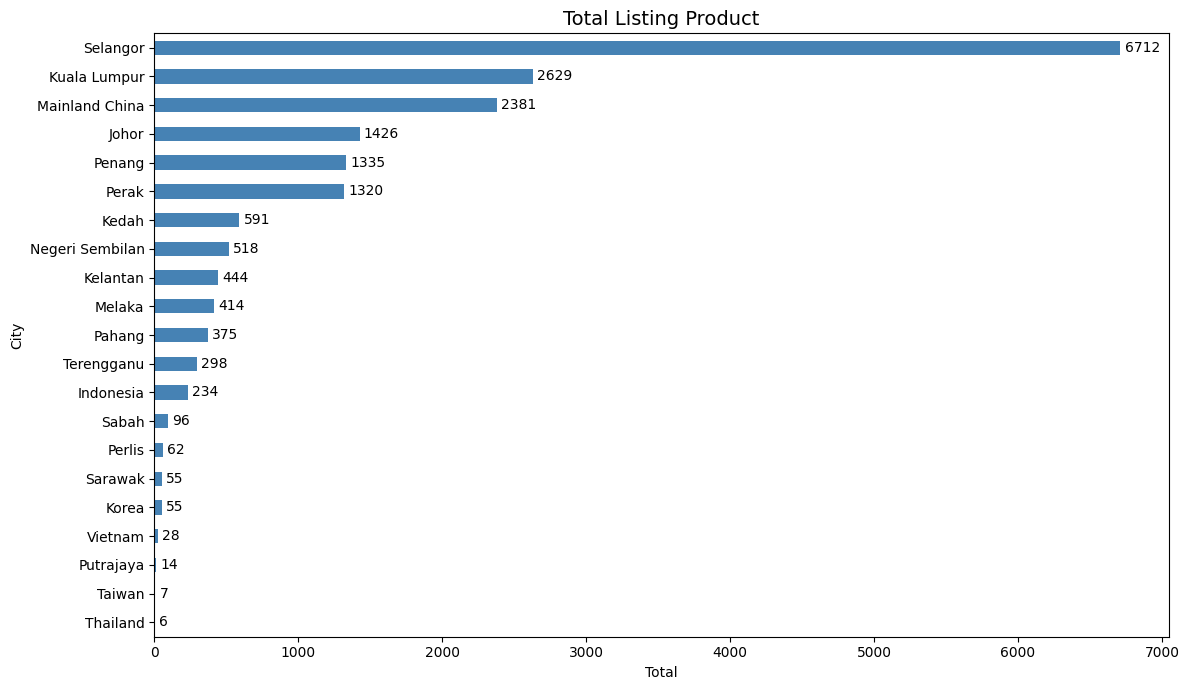

In [33]:
city_counts = df["city"].value_counts().sort_values()   # urut kecil -> besar agar yang terbanyak tampil di atas

ax = city_counts.plot.barh(figsize=(12, 7), color="steelblue")

ax.set_title("Total Listing Product", fontsize=14)
ax.set_xlabel("Total")
ax.set_ylabel("City")

# Tambahkan angka di ujung setiap bar
ax.bar_label(ax.containers[0], padding=3)

plt.tight_layout()
plt.show()

Dari hasil berikut dapat disimpulkan bahwa 
- 'Selangor' menjadikan kota dengan pengiriman produk terbanyak di negara Malaysia.
- Terdapat beberapa pengiriman product berasal dari negara lain selain Malaysia seperti China, Indonesia, Korea, Vietnam, Taiwan, Thailand

## Category Product

In [18]:
df['item_category_detail'].value_counts() # Cek value pada kolom

item_category_detail
Shopee | Mobile & Accessories | Others | Others                             185
Shopee | Mobile & Accessories | Tablets | Android Tablets                   184
Shopee | Men Clothes | Sets | Occupational Attire                           182
Shopee | Men Clothes | Others | Others                                      179
Shopee | Men Clothes | Shirts | Business & Casual Shirts                    175
                                                                           ... 
Shopee | Baby & Toys | Diapers & Potties | Others                             1
Shopee | Home Appliances | Large Kitchen Appliances | Microwaves              1
Shopee | Games, Books & Hobbies | Collectibles & Memorabilia | Local Pop      1
Shopee | Home Appliances | Small Kitchen Appliances | Egg Boilers             1
Shopee | Sports & Outdoor | Men's Sports Shoes | Basketball Shoes             1
Name: count, Length: 1147, dtype: int64

Pada kolom 'item_category_detail' terdapat beberapa value yang dipisah dengan tanda '|', dapat diasumsikan bahwa ada kategori dan sub kategori pada kolom tersebut, maka dari itu bisa dibuatkan kolom terpisah

In [19]:
category = df["item_category_detail"].str.split(r"\s*\|\s*", expand=True)

df["main_category"]     = category[1]   # contoh: Women's Bags
df["sub_category"]      = category[2]   # contoh: Shoulder Bags
df["second_sub_category"]  = category[3]   # contoh: Shoulder Bags

In [20]:
df["main_category"].value_counts()

main_category
Health & Beauty           2411
Men Clothes               2231
Women Clothes             2122
Mobile & Accessories      1802
Baby & Toys               1451
Home & Living             1275
Groceries & Pets          1098
Home Appliances            833
Automotive                 784
Sports & Outdoor           748
Women's Bags               600
Men's Bags & Wallets       440
Women Shoes                428
Muslim Fashion             416
Fashion Accessories        407
Watches                    405
Computer & Accessories     369
Cameras & Drones           337
Games, Books & Hobbies     330
Men Shoes                  192
Gaming & Consoles          136
Travel & Luggage           101
Tickets & Vouchers          69
Others                      44
Name: count, dtype: int64

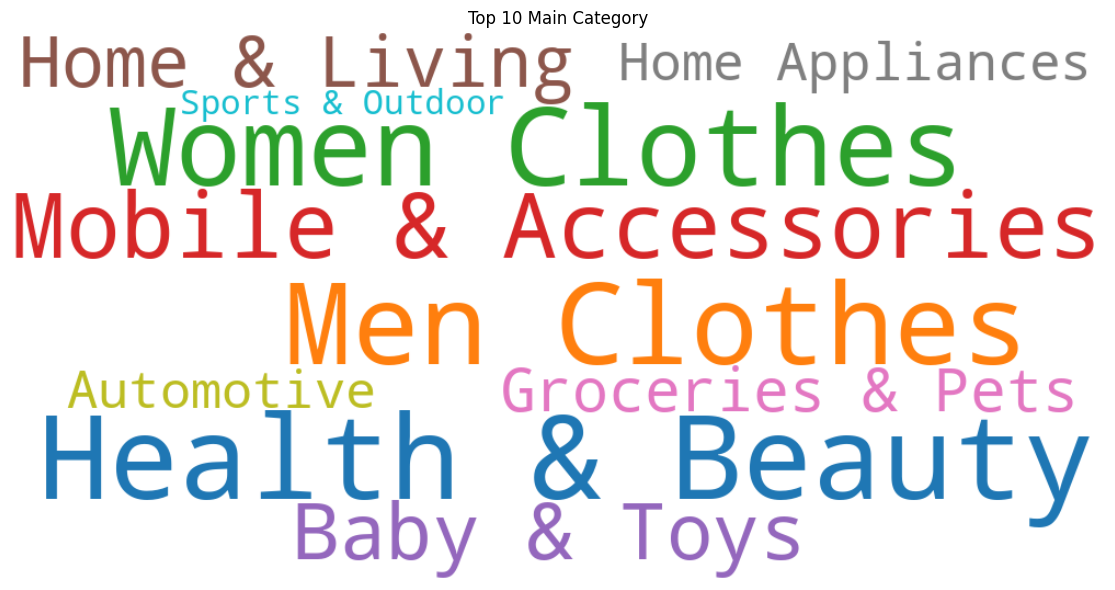

In [21]:
top10 = df["main_category"].value_counts().head(10)

# satu warna unik untuk setiap kategori
palette = plt.get_cmap("tab10").colors
color_map = {
    cat: tuple(int(c * 255) for c in palette[i])
    for i, cat in enumerate(top10.index)
}

# fungsi yang dipanggil WordCloud untuk menentukan warna tiap kata
def color_func(word, **kwargs):
    '''Fungsi ini untuk menampilkan warna pada wordcloud bervariasi'''
    r, g, b = color_map[word]
    return f"rgb({r}, {g}, {b})"

# buat word cloud dari frekuensi (dict: kategori -> jumlah)
wc = WordCloud(
    width=1000,
    height=500,
    background_color="white",
    colormap="viridis",
    random_state=42,
    color_func=color_func,
).generate_from_frequencies(top10.to_dict())

# tampilkan grafik wordcloud
plt.figure(figsize=(12, 6))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Top 10 Main Category")
plt.tight_layout()
plt.show()

'Health & Beauty" menjadikan barang yang paling banyak dipesan selama periode Maret - April 2023

## Check Structure Hierarky

In [22]:
# Agregasi: jumlah produk & median harga per main_category + sub_category
agg = (
    df.groupby(["main_category", "sub_category"])
      .agg(n_produk=("price_ori", "size"),
           median_price=("price_ori", "median")) # Gunakan nilai median, bukan rata-rata, karena distribusinya miring
      .reset_index()
)

# Buat menjadi Top 10 kategori utama agar grafik tidak penuh
TOP_N = 10
top_cats = agg.groupby("main_category")["n_produk"].sum().nlargest(TOP_N).index
agg = agg[agg["main_category"].isin(top_cats)]

# Warna pakai log10 supaya outlier tidak mendominasi skala warna
agg["log_median"] = np.log10(agg["median_price"])

# Grafik Treemap
fig = px.treemap(
    agg,
    path=[px.Constant("Semua Kategori"), "main_category", "sub_category"],
    values="n_produk",
    color="log_median",
    color_continuous_scale="RdYlGn_r",
    custom_data=["median_price", "n_produk"],
    title=f"Top {TOP_N} berdasarkan kategori produk (Jumlah Produk dan Median Harga)" ,
)
fig.update_traces(
    hovertemplate="<b>%{label}</b><br>Jumlah produk: %{customdata[1]:,}"
                  "<br>Median price_ori: %{customdata[0]:,.2f}<extra></extra>"
)
fig.update_layout(
    margin=dict(t=60, l=10, r=10, b=10),
    coloraxis_colorbar=dict(title="log10(median)"),
)
fig.show()

- 'Health & Beauty menjadikan katergori dengan banyak pemesanan
- Warna pada value menentukan seberapa besar nilai median pada harga
- Value 'Automotive' menjadikan warna menjadi merah pekat karena harga otomotif sangat berbeda jauh dengan harga lainnya

## Check Correlation

Mengecek korelasi antara kolom numeric

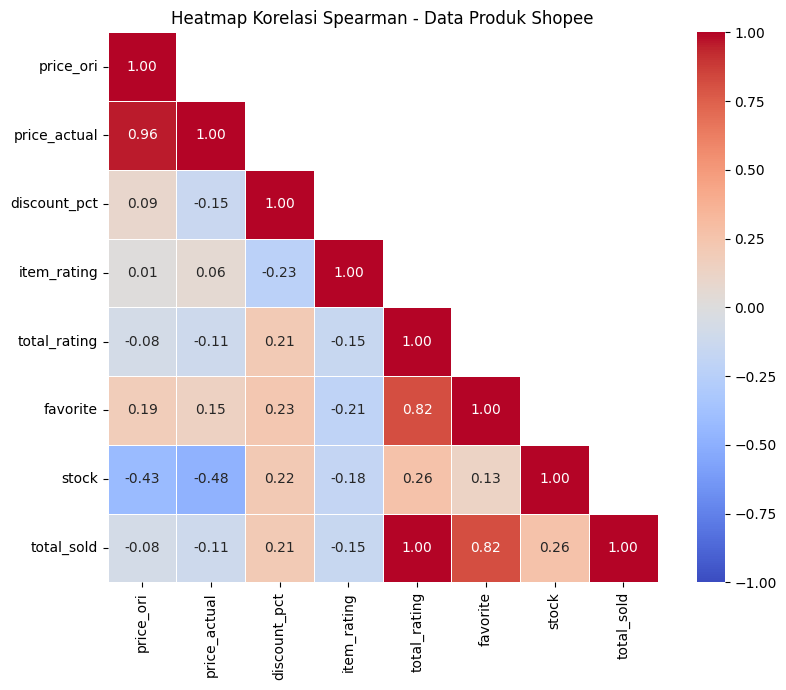

In [23]:
def parse_k(x):
    """ Fungsi ini untuk mengkonversikan nilai yang mengandung bentuk ribuan (k) menjadi value yang seharusnya, serta merubah kolom menjadi numeric"""
    if pd.isna(x): return np.nan
    m = re.search(r"([\d.,]+)\s*([kKmM]?)", str(x))
    if not m: return np.nan
    num = float(m.group(1).replace(",", ""))
    return num * {"k": 1e3, "m": 1e6}.get(m.group(2).lower(), 1)

df["item_rating"]  = pd.to_numeric(df["item_rating"], errors="coerce") # mengubah kolom menjadi numerik
df["total_rating"] = df["total_rating"].apply(parse_k) # Implant fungsi parse_k
df["favorite"]     = df["favorite"].apply(parse_k) # Implant fungsi parse_k
df["total_sold"]   = df["total_sold"].apply(parse_k) # mengubah kolom menjadi numerik

df = df[(df.price_ori.between(0, 1_000_000, inclusive="neither")) &
        (df.price_actual.between(0, 1_000_000, inclusive="neither"))]
df["discount_pct"] = (1 - df.price_actual / df.price_ori) * 100 # Kolom diskon dibuat sebagai acuan dari nilai price_ori dan price_actual

cols = ["price_ori", "price_actual", "discount_pct", "item_rating", "total_rating", "favorite", "stock", "total_sold"]
data = df[cols].copy()
for c in ["price_ori", "price_actual", "total_rating", "favorite", "stock"]:
    data[c] = np.log1p(data[c])

corr = data.corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
plt.figure(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, linewidths=.5)
plt.title("Heatmap Korelasi Spearman - Data Produk Shopee")
plt.tight_layout()

- 'price_ori' dan 'price_actual' mempunyai korelasi yang kuat. Ini dikarenakan nilai harga aktual sangat berpengaruh dari nilai awal dengan tergantung seberapa besar diskon yang diberikan
- 'total_sold dan 'total_rating' sangat berkorelasi, dapat disimpulkan bahwa semua customer yang sudah menerima product yang dipesan langsung memberikan rating pada product tersebut
- 'total_sold dan 'total_rating' mempunyai korelasi yang kuat dengan 'favorite', ini menjadikan semakin banyak product yang terjual dan memberikan rating, maka semakin besar chance product tersebut difavoritkan banyak orang

## Check Most Category product Sale per City

Hasil berikut menampilkan beberapa catergory penjualan berdasarkan kota. Ini bisa dijadikan perhatian kepada para Seller untuk memastikan jenis category apa yang ingin dijual

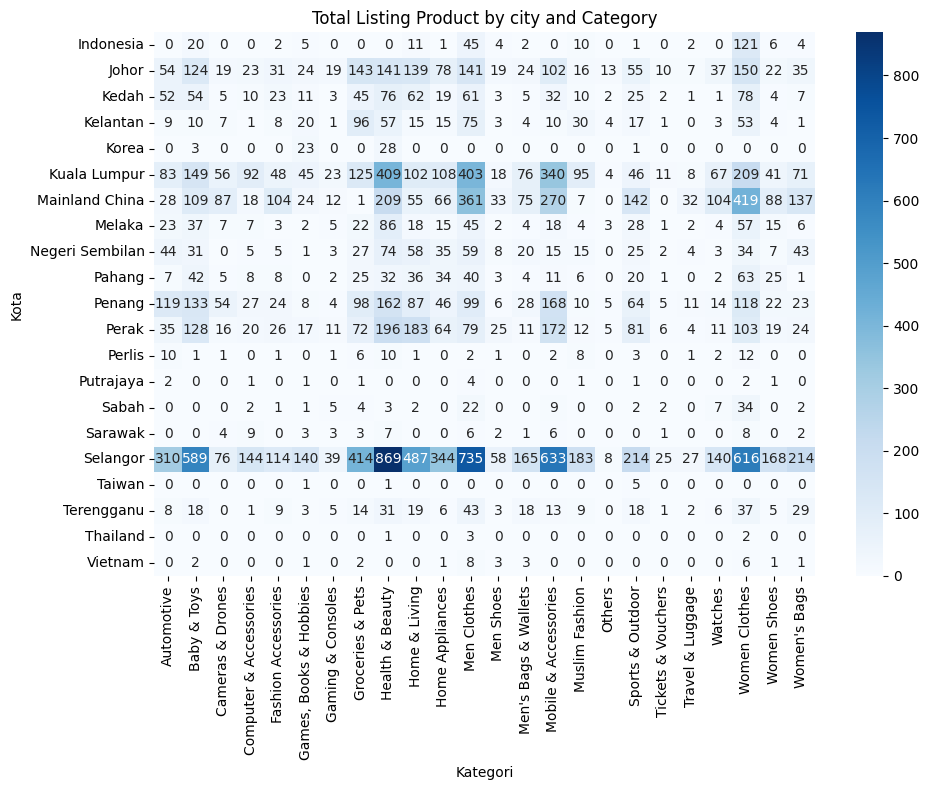

In [24]:
tabel = pd.crosstab(df['city'], df['main_category'])

plt.figure(figsize=(10, 8))
sns.heatmap(tabel, annot=True, fmt='d', cmap='Blues')
plt.title('Total Listing Product by city and Category')
plt.xlabel('Kategori')
plt.ylabel('Kota')
plt.tight_layout()
plt.show()

## Listing Product by Discount

C:\Users\ASUS\AppData\Local\Temp\ipykernel_25232\4184391887.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  hasil = df.groupby('discount_bin')['total_sold'].median().reset_index()


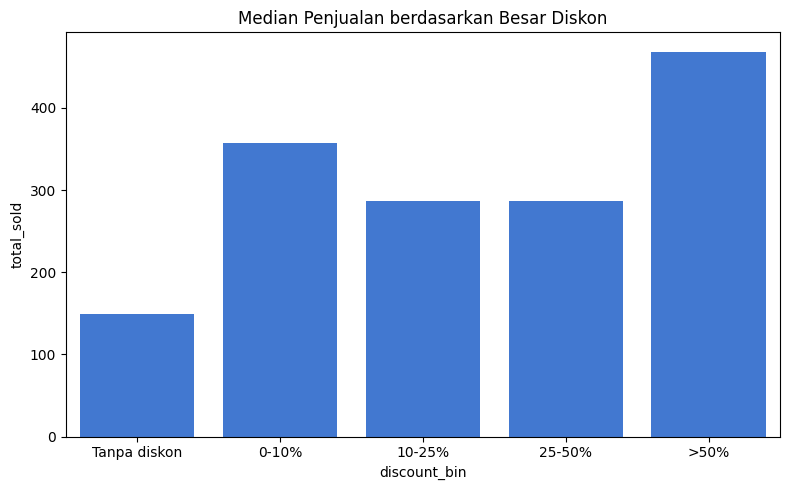

In [25]:
df['discount_bin'] = pd.cut(df['discount_pct'],
                            bins=[-1, 0, 10, 25, 50, 100],
                            labels=['Tanpa diskon', '0-10%', '10-25%', '25-50%', '>50%'])

hasil = df.groupby('discount_bin')['total_sold'].median().reset_index()

plt.figure(figsize=(8, 5))
sns.barplot(data=hasil, x='discount_bin', y='total_sold', color="#2a73e8aa")
plt.title('Median Penjualan berdasarkan Besar Diskon')
plt.tight_layout()
plt.show()

In [26]:
df.to_csv('Shoppe_Sales_1.csv', index=False)

# Insight Business

- Para Seller bisa membangun banyak relasi atau kerja sama seperti Affiliate / Dropshiper dengan para produsen di sekitar wilayah Selangor atau Kuala Lumpur agar bisa mengamankan ketersediaan stock barang
- Pengusaha bisa membangun pabrik di sekitar wilayah dengan pengiriman terbanyak agar meningkatkan kepercayaan pada buyer
- Para Seller bisa memberikan informasi kepada Buyer untuk bisa memberikan rating yang sesuai dengan kepuasannya jika sudah menerima dan mereview product tersebut
- Buat label diskon atau promo harga pada suatu product. Karena walaupun besarnya diskon tidak mempengaruhi kuat bahwa buyer menjadi tertarik beli, namun efek psikologis yang memberikan tanda diskon atau coret harga yang membuat para buyer menjadi merasa bahwa product tersebut menjadi murah dan kesempatan untuk segera membeli barang tersebut